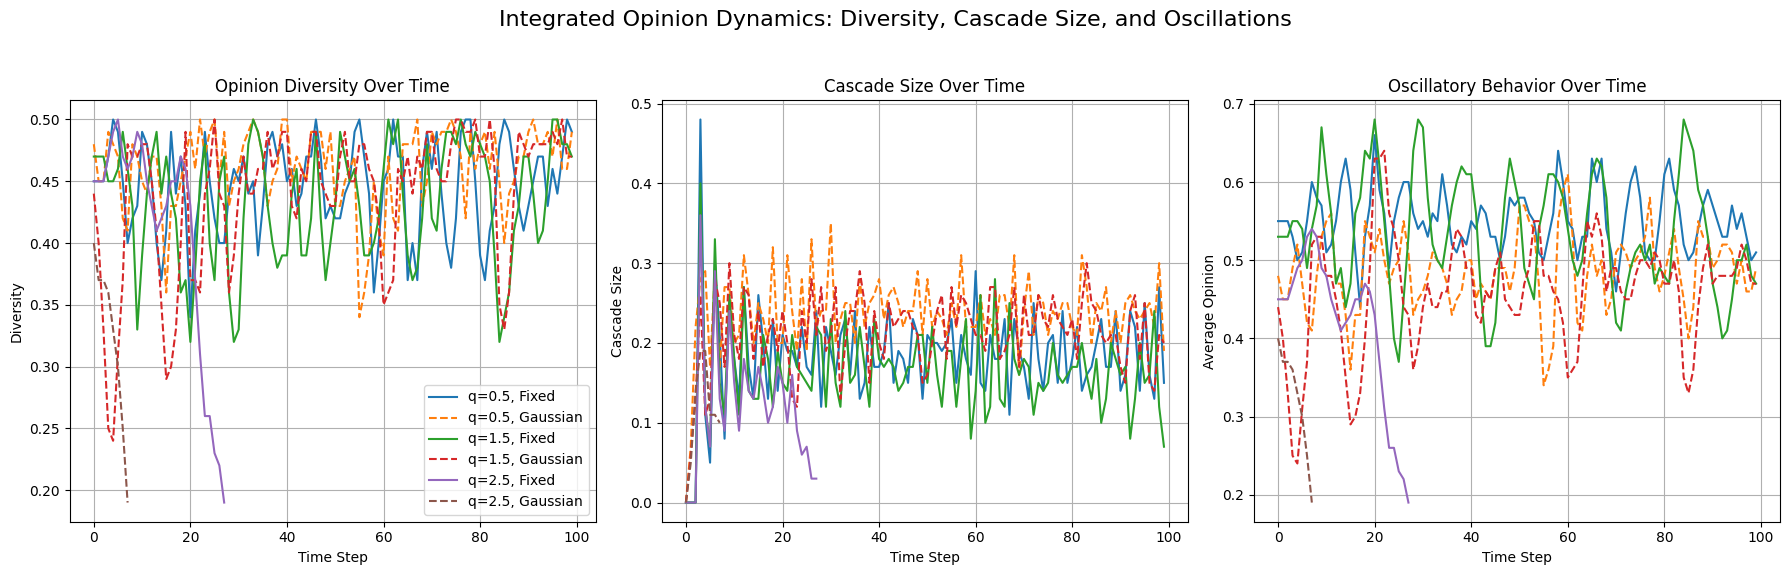

In [8]:
import numpy as np
import random
import matplotlib.pyplot as plt

class HNLVoterModel:
    def __init__(self, nodes, hyperedges, influence_weights, q, latencies, consensus_threshold):
        self.nodes = nodes
        self.hyperedges = hyperedges
        self.influence_weights = influence_weights
        self.q = q
        self.latencies = latencies
        self.consensus_threshold = consensus_threshold
        self.opinions = np.random.choice([0, 1], size=len(nodes))  # Initial random opinions
        self.last_change_time = np.zeros(len(nodes))  # Track last opinion change time
        self.time_step = 0
        self.history = []  # Metrics: diversity, cascade size, oscillations

    def compute_influence_scores(self, edge):
        S_0 = sum(self.influence_weights[j] for j in edge if self.opinions[j] == 0)
        S_1 = sum(self.influence_weights[j] for j in edge if self.opinions[j] == 1)
        return S_0, S_1

    def update_opinions(self):
        new_opinions = self.opinions.copy()
        for edge in self.hyperedges:
            S_0, S_1 = self.compute_influence_scores(edge)
            S_0, S_1 = S_0 ** self.q, S_1 ** self.q
            for node in edge:
                if self.time_step - self.last_change_time[node] >= self.latencies[node]:
                    P_1 = S_1 / (S_0 + S_1) if (S_0 + S_1) > 0 else 0.5
                    new_opinions[node] = 1 if random.random() < P_1 else 0
                    if new_opinions[node] != self.opinions[node]:
                        self.last_change_time[node] = self.time_step
        self.opinions = new_opinions

    def compute_metrics(self):
        n_0 = np.sum(self.opinions == 0)
        n_1 = np.sum(self.opinions == 1)
        diversity = 1 - max(n_0, n_1) / len(self.nodes)
        if self.time_step > 0 and len(self.history) > 0:
            cascade_size = np.sum(self.opinions != self.history[-1]["opinions"]) / len(self.nodes)
        else:
            cascade_size = 0
        oscillation = np.mean(self.opinions)
        return diversity, cascade_size, oscillation
    
    def run_simulation(self, max_steps=100):
        """Run the simulation and record metrics."""
        for self.time_step in range(1, max_steps + 1):
            diversity, cascade_size, oscillation = self.compute_metrics()
            self.history.append({
                "diversity": diversity,
                "cascade_size": cascade_size,
                "oscillation": oscillation,
                "opinions": self.opinions.copy()  # Add this back
            })
            if np.mean(self.opinions) >= self.consensus_threshold or np.mean(self.opinions) <= 1 - self.consensus_threshold:
                break
            self.update_opinions()
        return self.history



# Parameters for Testing
num_nodes = 100
nodes = np.arange(num_nodes)
hyperedges = [random.sample(range(num_nodes), k=random.randint(5, 15)) for _ in range(10)]
influence_weights = np.ones(num_nodes)  # Equal influence weights

# Latency distributions
latency_fixed = np.full(num_nodes, 3)
latency_gaussian = np.clip(np.random.normal(3, 1, size=num_nodes), 1, None).astype(int)

# Test different q and latency settings
q_values = [0.5, 1.5, 2.5]
latency_settings = {"Fixed": latency_fixed, "Gaussian": latency_gaussian}

# Colors and Linestyles for Plotting
colors = ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple", "tab:brown"]
linestyles = ["-", "--"]
labels = []

# Integrated Plot
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle("Integrated Opinion Dynamics: Diversity, Cascade Size, and Oscillations", fontsize=16)

for idx, q in enumerate(q_values):
    for jdx, (latency_label, latency) in enumerate(latency_settings.items()):
        label = f"q={q}, {latency_label}"
        labels.append(label)
        
        model = HNLVoterModel(
            nodes=nodes,
            hyperedges=hyperedges,
            influence_weights=influence_weights,
            q=q,
            latencies=latency,
            consensus_threshold=0.8
        )
        history = model.run_simulation(max_steps=100)
        
        diversity = [h["diversity"] for h in history]
        cascade_size = [h["cascade_size"] for h in history]
        oscillation = [h["oscillation"] for h in history]

        # Plot Diversity
        axes[0].plot(diversity, color=colors[idx*2 + jdx], linestyle=linestyles[jdx], label=label)

        # Plot Cascade Size
        axes[1].plot(cascade_size, color=colors[idx*2 + jdx], linestyle=linestyles[jdx])

        # Plot Oscillatory Behavior
        axes[2].plot(oscillation, color=colors[idx*2 + jdx], linestyle=linestyles[jdx])

# Setting Titles, Labels, and Legends
axes[0].set_title("Opinion Diversity Over Time")
axes[0].set_xlabel("Time Step")
axes[0].set_ylabel("Diversity")
axes[0].grid()
axes[0].legend()

axes[1].set_title("Cascade Size Over Time")
axes[1].set_xlabel("Time Step")
axes[1].set_ylabel("Cascade Size")
axes[1].grid()

axes[2].set_title("Oscillatory Behavior Over Time")
axes[2].set_xlabel("Time Step")
axes[2].set_ylabel("Average Opinion")
axes[2].grid()

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()
